# Fully online end-to-end AMC inference: 2018train20

Each test signal is read from its raw `.tim` IQ file and independently follows BOI detection/frequency shifting, three FFT representations, LR55 coarse classification, and—only for the QPSK-like route—blind $R_s$/CFO estimation, $11\times24$ CC construction, $11\times15$ cropping, and CAPNet fine classification. Ground-truth labels are used only for the 2018 negative-SNR exclusion rule and final evaluation.

The two evaluated splits are: (1) CSPB.ML.2018 batches 25–28 and (2) the complete CSPB.ML.2022 dataset. Results are checkpointed so a long run can resume safely.

In [1]:
from pathlib import Path
import sys


def _find_helper_project_dir(start=Path.cwd()):
    start = Path(start).resolve()
    search_roots = [start, *start.parents]
    for root in search_roots:
        if (root / "helper_function" / "__init__.py").exists():
            return root
    for root in search_roots[:3]:
        matches = list(root.glob("**/boi_shift_fft3_cfpattern_spl/helper_function/__init__.py"))
        if matches:
            return matches[0].parent.parent
    raise FileNotFoundError("Could not find helper_function from the current Jupyter working directory.")


PROJECT_DIR = _find_helper_project_dir()
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from helper_function.fully_online_pipeline_inference import (
    FullyOnlinePipeline,
    make_default_config,
    print_and_plot_cm,
)

BASE_DIR = PROJECT_DIR
DATASET_ROOT = (BASE_DIR / '../../CSPB.ML_dataset').resolve()
MODEL_DIR = BASE_DIR / 'fully_online_pipeline_models'
RESULT_DIR = BASE_DIR / 'fully_online_inference_results' / '2018train20'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

CFG = make_default_config(DATASET_ROOT)
pipeline = FullyOnlinePipeline(
    dataset_root=DATASET_ROOT,
    model_dir=MODEL_DIR,
    split_mode='2018train20',
    cfg=CFG,
)

print('Dataset root:', DATASET_ROOT)
print('LR model:', pipeline.lr_path)
print('CAP model:', pipeline.cap_path)
print('Device:', pipeline.device)
print('LR feature count:', len(pipeline.lr_feature_names))

Dataset root: /home/ruilin/SPL_Surreal/CSPB.ML_dataset
LR model: /home/ruilin/SPL_Surreal/SPL_code/boi_shift_fft3_cfpattern_spl/fully_online_pipeline_models/lr55_2018train20.joblib
CAP model: /home/ruilin/SPL_Surreal/SPL_code/boi_shift_fft3_cfpattern_spl/fully_online_pipeline_models/capnet_2018train20.pt
Device: cuda:0
LR feature count: 55


## Confusion matrix 1: 2018 held-out batches 25–28

2018train20: 2018:   0%|          | 0/40 [00:00<?, ?signal/s]

2018train20: CSPB.ML.2018 batches 25–28: N=15,960, accuracy=0.906516, QPSK-like route=0.4997


,BPSK,MSK,DQPSK,8PSK,QPSK,16QAM,64QAM,256QAM
BPSK,1995,0,0,0,0,0,0,0
MSK,0,1995,0,0,0,0,0,0
DQPSK,0,0,1995,0,0,0,0,0
8PSK,0,0,0,1994,0,1,0,0
QPSK,0,0,3,0,1992,0,0,0
16QAM,0,0,0,0,0,1893,95,7
64QAM,0,0,0,2,0,92,1243,658
256QAM,0,0,1,0,0,24,609,1361


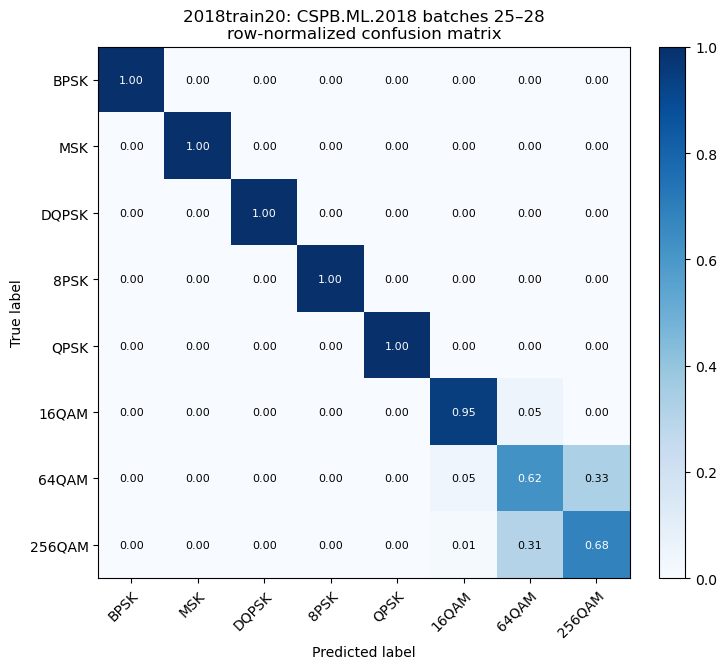

In [2]:
results_2018 = pipeline.run_dataset(
    year=2018,
    batch_ids=range(25, 29),
    output_csv=RESULT_DIR / '2018_batches25_28_predictions.csv',
    resume=True,
    checkpoint_every=100,
    fail_fast=True,
)
cm_2018 = print_and_plot_cm(results_2018, '2018train20: CSPB.ML.2018 batches 25–28')

## Confusion matrix 2: complete 2022 cross-domain test set

2018train20: 2022: 0signal [00:00, ?signal/s]

2018train20: complete CSPB.ML.2022 cross-domain test: N=112,000, accuracy=0.914518, QPSK-like route=0.5002


,BPSK,MSK,DQPSK,8PSK,QPSK,16QAM,64QAM,256QAM
BPSK,14000,0,0,0,0,0,0,0
MSK,0,14000,0,0,0,0,0,0
DQPSK,0,0,14000,0,0,0,0,0
8PSK,0,1,0,13931,47,4,17,0
QPSK,0,0,40,0,13960,0,0,0
16QAM,0,0,0,0,50,13643,291,16
64QAM,0,0,0,1,10,585,9493,3911
256QAM,0,0,0,2,5,240,4354,9399


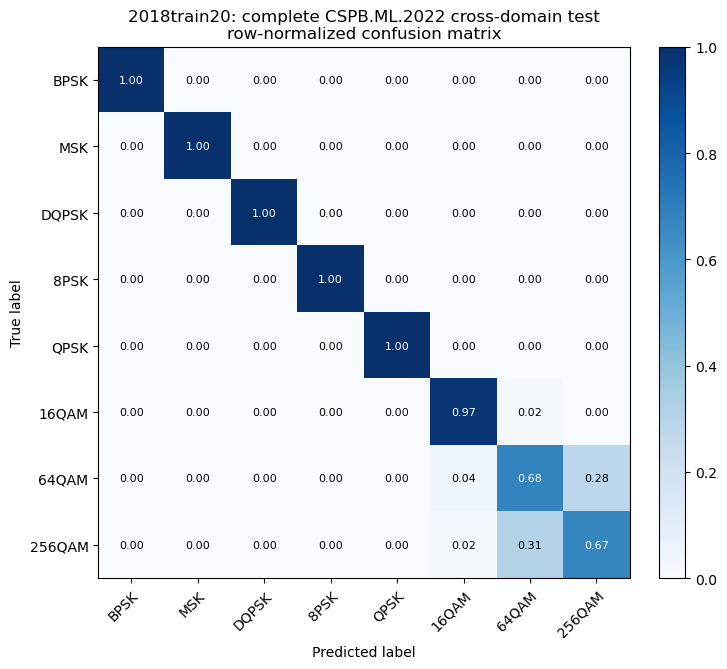

In [3]:
results_2022 = pipeline.run_dataset(
    year=2022,
    batch_ids=range(1, 29),
    output_csv=RESULT_DIR / '2022_all_predictions.csv',
    resume=True,
    checkpoint_every=100,
    fail_fast=True,
)
cm_2022 = print_and_plot_cm(results_2022, '2018train20: complete CSPB.ML.2022 cross-domain test')

## Confusion Matrix

2018 test: N = 15,960, Acc = 90.65%
2022 test: N = 112,000, Acc = 91.45%


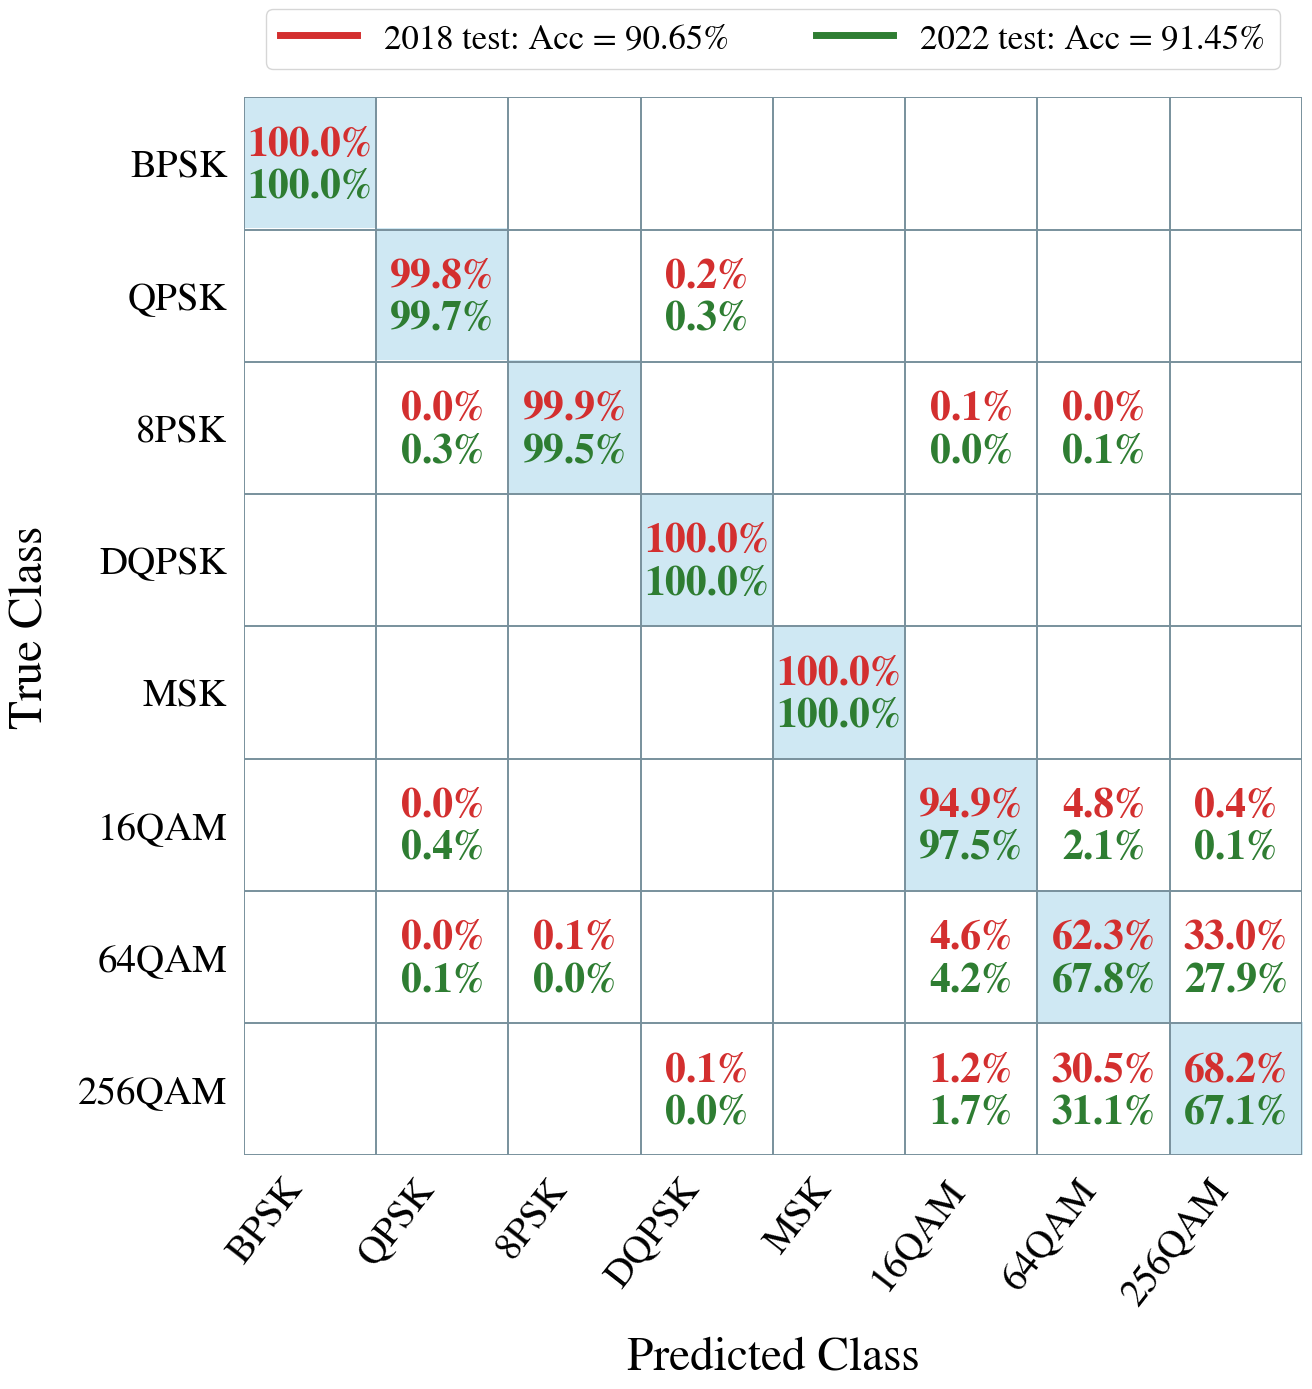

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from sklearn.metrics import confusion_matrix

plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
})

PLOT_CLASS_ORDER = [
    "BPSK",
    "QPSK",
    "8PSK",
    "DQPSK",
    "MSK",
    "16QAM",
    "64QAM",
    "256QAM",
]

def row_normalize_cm(cm):
    cm = np.asarray(cm, dtype=np.float64)
    row_sum = cm.sum(axis=1, keepdims=True)
    row_sum[row_sum == 0] = 1.0
    return cm / row_sum * 100.0

def cm_acc_from_results(results, class_order=PLOT_CLASS_ORDER):
    df = results.copy()

    if "pred_label" not in df.columns or "true_label" not in df.columns:
        raise ValueError("results must contain true_label and pred_label columns.")

    if df["pred_label"].astype(str).eq("ERROR").any():
        n_err = int(df["pred_label"].astype(str).eq("ERROR").sum())
        raise RuntimeError(f"Found {n_err} ERROR samples. Inspect results before plotting.")

    if "error" in df.columns:
        bad = df["error"].fillna("").astype(str).str.len() > 0
        if bad.any():
            raise RuntimeError(f"Found {int(bad.sum())} non-empty error rows. Inspect results before plotting.")

    y_true = df["true_label"].astype(str).str.strip()
    y_pred = df["pred_label"].astype(str).str.strip()

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=class_order,
    )

    acc = np.mean(y_true.to_numpy() == y_pred.to_numpy()) * 100.0
    return cm, acc

def plot_combined_confusion(
    cm_2018,
    cm_2022,
    acc_2018,
    acc_2022,
    class_names=PLOT_CLASS_ORDER,
    save_path=None,
):
    cm_2018_pct = row_normalize_cm(cm_2018)
    cm_2022_pct = row_normalize_cm(cm_2022)

    n_classes = len(class_names)
    background = np.eye(n_classes)

    cmap = ListedColormap([
        "#FFFFFF",
        "#CFE8F3",
    ])

    fig, ax = plt.subplots(figsize=(16, 14))

    ax.imshow(
        background,
        cmap=cmap,
        vmin=0,
        vmax=1,
        interpolation="nearest",
        aspect="equal",
    )

    ax.set_xticks(np.arange(-0.5, n_classes, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n_classes, 1), minor=True)

    ax.grid(
        which="minor",
        color="#78909C",
        linestyle="-",
        linewidth=1.4,
    )
    ax.tick_params(which="minor", bottom=False, left=False)

    ax.set_xticks(np.arange(n_classes))
    ax.set_yticks(np.arange(n_classes))

    ax.set_xticklabels(
        class_names,
        rotation=52,
        ha="right",
        fontsize=28,
    )
    ax.set_yticklabels(
        class_names,
        fontsize=28,
    )

    ax.set_xlabel(
        "Predicted Class",
        fontsize=34,
        labelpad=18,
    )
    ax.set_ylabel(
        "True Class",
        fontsize=34,
        labelpad=18,
    )

    for i in range(n_classes):
        for j in range(n_classes):
            value_2018 = cm_2018_pct[i, j]
            value_2022 = cm_2022_pct[i, j]

            if round(value_2018, 1) == 0.0 and round(value_2022, 1) == 0.0:
                continue

            ax.text(
                j,
                i - 0.14,
                f"{value_2018:.1f}%",
                ha="center",
                va="center",
                color="#D32F2F",
                fontsize=30,
                fontweight="bold",
            )

            ax.text(
                j,
                i + 0.18,
                f"{value_2022:.1f}%",
                ha="center",
                va="center",
                color="#2E7D32",
                fontsize=30,
                fontweight="bold",
            )

    legend_handles = [
        Line2D(
            [0], [0],
            color="#D32F2F",
            linewidth=5,
            label=f"2018 test: Acc = {acc_2018:.2f}%",
        ),
        Line2D(
            [0], [0],
            color="#2E7D32",
            linewidth=5,
            label=f"2022 test: Acc = {acc_2022:.2f}%",
        ),
    ]

    ax.legend(
        handles=legend_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 1.01),
        ncol=2,
        frameon=True,
        fontsize=25,
        handlelength=2.2,
        columnspacing=2.5,
    )

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(axis="both", which="major", length=0, pad=12)

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=600,
            bbox_inches="tight",
            facecolor="white",
        )

    plt.show()


cm_2018, acc_2018 = cm_acc_from_results(results_2018)
cm_2022, acc_2022 = cm_acc_from_results(results_2022)

print(f"2018 test: N = {len(results_2018):,}, Acc = {acc_2018:.2f}%")
print(f"2022 test: N = {len(results_2022):,}, Acc = {acc_2022:.2f}%")

plot_combined_confusion(
    cm_2018=cm_2018,
    cm_2022=cm_2022,
    acc_2018=acc_2018,
    acc_2022=acc_2022,
    class_names=PLOT_CLASS_ORDER,
    save_path=None,
    # save_path="combined_confusion_matrix.pdf",
)

This benchmark profiles exactly 64 true QPSK-like target signals (`QPSK`, `16QAM`, `64QAM`, `256QAM`) in one chunk. It does not read BOI/FFT/CC cache. CPU keeps all operations on CPU. GPU reads `.tim` files on CPU, transfers the full batch to one RTX 3090, keeps BOI/shift, required-only FFT3 LR55/RS20/CFO1 vector generation, LR, Rs-CFO, low-complexity QPSK `11x15` CC construction, and CAPNet on GPU.


In [5]:
import gc
import time

import numpy as np
import pandas as pd
import torch

from helper_function import pre_cc_matrix_core_from_old as cc
from helper_function import pre_compact_fft3_vector_generator as compact
from helper_function import pre_qpsklike_rs_cfo_estimator as rc
from helper_function.fully_online_pipeline_inference import (
    FullyOnlinePipeline as FullyOnlinePipelineCPU,
    _boi_preprocess as _boi_preprocess_cpu,
    _cc_power as _cc_power_cpu,
    _truth_column,
    load_truth_table,
)
from helper_function.fully_online_pipeline_inference_gpu import (
    FullyOnlinePipelineGPU,
    _cc_power as _cc_power_gpu,
    _estimate_rs_cfo_from_torch_vectors,
    boi_preprocess_torch,
)
from helper_function.qpsk_cc_11x15_fast import build_qpsk_cap_input_11x15_torch

TIMING_YEAR = 2018
TIMING_BATCH_IDS = [25]
TIMING_SIGNAL_LIMIT = 64
TIMING_TRUE_QPSKLIKE_LABELS = {"QPSK", "16QAM", "64QAM", "256QAM"}
DROP_2018_NEGATIVE_SNR = True
GPU_DEVICE = "cuda:0"

STAGE_COLUMNS = [
    "load_s",
    "boi_shift_s",
    "fft3_lr_feature_s",
    "lr_s",
    "rs_cfo_s",
    "cc_s",
    "cap_s",
]


def _eligible_qpsklike_indices(year, batch_ids, limit):
    truth = load_truth_table(DATASET_ROOT, int(year))
    label_col = _truth_column(
        truth,
        ["SignalType", "signal_type", "signal type", "modulation", "modulation_type", "label"],
    )
    snr_col = _truth_column(
        truth,
        ["InbandSNRdB", "inband_snr_db_label", "inband snr db label", "snr", "snr_db"],
    )
    out = []
    for batch_id in batch_ids:
        start = (int(batch_id) - 1) * int(CFG["N_PER_BATCH"]) + 1
        stop = min(int(batch_id) * int(CFG["N_PER_BATCH"]), int(CFG["N_TOTAL"]))
        for signal_index in range(start, stop + 1):
            true_label = str(truth.loc[signal_index, label_col]).strip().upper()
            if true_label not in TIMING_TRUE_QPSKLIKE_LABELS:
                continue
            if int(year) == 2018 and DROP_2018_NEGATIVE_SNR:
                if float(truth.loc[signal_index, snr_col]) < 0.0:
                    continue
            out.append(int(signal_index))
            if len(out) >= int(limit):
                return out
    raise ValueError(f"Only found {len(out)} eligible QPSK-like signals; need {limit}.")


def _sync_device(device):
    device = torch.device(device)
    if device.type == "cuda":
        torch.cuda.synchronize(device)


def _round_seconds(df):
    out = df.copy()
    numeric_cols = out.select_dtypes(include=[np.number]).columns
    out[numeric_cols] = out[numeric_cols].round(6)
    return out


def _profile_cpu_qpsklike_branch(pipeline_obj, year, signal_indices):
    gc.collect()
    cc.configure_cc_runtime(USE_CUDA=False)
    timings = {}
    total_t0 = time.perf_counter()

    t0 = time.perf_counter()
    x_batch = pipeline_obj.load_signal_batch(year, signal_indices)
    timings["load_s"] = time.perf_counter() - t0

    staged = []
    t0 = time.perf_counter()
    for x in x_batch:
        x_processed, prepared, center_shift_hz = _boi_preprocess_cpu(x, pipeline_obj.cfg)
        staged.append({
            "x_processed": x_processed,
            "prepared": prepared,
            "center_shift_hz": center_shift_hz,
        })
    timings["boi_shift_s"] = time.perf_counter() - t0

    lr_rows = []
    t0 = time.perf_counter()
    for item in staged:
        lr55, rs20, cfo1 = pipeline_obj._blind_vectors(item["x_processed"], item["center_shift_hz"])
        item["rs20"] = rs20
        item["cfo1"] = cfo1
        lr_rows.append(lr55)
    lr_matrix = np.stack(lr_rows, axis=0).astype(np.float32, copy=False)
    timings["fft3_lr_feature_s"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    _ = pipeline_obj.lr_model.predict(lr_matrix)
    timings["lr_s"] = time.perf_counter() - t0

    estimates = []
    t0 = time.perf_counter()
    for item in staged:
        x_processed_cc = np.asarray(item["x_processed"], dtype=np.complex64)
        compact_sample = {
            "x_processed": x_processed_cc,
            "vectors": {"rs20": item["rs20"], "cfo1": item["cfo1"]},
        }
        estimates.append(
            rc.estimate_rs_cfo_from_sample(
                compact_sample,
                compact.RS20_FEATURES,
                compact.CFO_FEATURES,
                set(),
                rs_vector_key="rs20",
            )
        )
    timings["rs_cfo_s"] = time.perf_counter() - t0

    cap_inputs = []
    t0 = time.perf_counter()
    for item, estimate in zip(staged, estimates):
        x_processed_cc = np.asarray(item["x_processed"], dtype=np.complex64)
        raw_cc = cc.build_estimated_cc_matrix_11x24_from_signal_pattern(
            np.asarray(x_processed_cc, dtype=np.complex128),
            float(estimate["T0_est"]),
            float(estimate["cfo_est"]),
            cc.qpsk,
            remove_mean=False,
            max_k=5,
        )
        power = _cc_power_cpu(item["prepared"], item["x_processed"], float(pipeline_obj.cfg["EPS"]))
        _, cc_abs = cc.apply_cc_postprocessing_with_power(
            raw_cc["matrix_complex"],
            power,
            cc.CC_NM,
            enable_warping=True,
            enable_scaling=False,
            is_theory=False,
            eps=float(pipeline_obj.cfg["EPS"]),
        )
        cap_inputs.append(np.asarray(cc_abs[:, :15], dtype=np.float32) / np.float32(power))
    timings["cc_s"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    cap_array = np.stack(cap_inputs, axis=0).astype(np.float32, copy=False)
    cap_tensor = torch.from_numpy(cap_array[:, None, :, :]).to(pipeline_obj.device)
    with torch.inference_mode():
        _ = pipeline_obj.cap_model(cap_tensor).argmax(dim=1).detach().cpu().numpy()
    timings["cap_s"] = time.perf_counter() - t0

    total_s = time.perf_counter() - total_t0
    return {
        "device": "cpu",
        "n_samples": int(len(signal_indices)),
        **timings,
        "total_s": total_s,
        "per_sample_s": total_s / max(len(signal_indices), 1),
    }


def _profile_gpu_qpsklike_branch(pipeline_obj, year, signal_indices):
    gc.collect()
    torch.cuda.empty_cache()
    timings = {}
    device = pipeline_obj.device
    _sync_device(device)
    total_t0 = time.perf_counter()

    t0 = time.perf_counter()
    x_batch = pipeline_obj.load_signal_batch(year, signal_indices)
    _sync_device(device)
    timings["load_s"] = time.perf_counter() - t0

    staged = []
    t0 = time.perf_counter()
    for row_idx in range(int(x_batch.shape[0])):
        x_processed, prepared, center_shift_hz = boi_preprocess_torch(x_batch[row_idx], pipeline_obj.cfg)
        staged.append({
            "x_processed": x_processed,
            "prepared": prepared,
            "center_shift_hz": center_shift_hz,
        })
    _sync_device(device)
    timings["boi_shift_s"] = time.perf_counter() - t0

    lr_rows = []
    rs20_rows = []
    cfo1_rows = []
    t0 = time.perf_counter()
    for item in staged:
        lr55, rs20, cfo1 = pipeline_obj._blind_vectors(item["x_processed"], item["center_shift_hz"])
        item["rs20"] = rs20
        item["cfo1"] = cfo1
        lr_rows.append(lr55)
        rs20_rows.append(rs20)
        cfo1_rows.append(cfo1)
    x_processed_batch = torch.stack([item["x_processed"] for item in staged], dim=0)
    rs20_batch = torch.stack(rs20_rows, dim=0)
    cfo1_batch = torch.stack(cfo1_rows, dim=0)
    lr_matrix = torch.stack(lr_rows, dim=0)
    _sync_device(device)
    timings["fft3_lr_feature_s"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    _ = pipeline_obj.lr_model.predict_indices(lr_matrix)
    _sync_device(device)
    timings["lr_s"] = time.perf_counter() - t0

    estimates = []
    t0 = time.perf_counter()
    for row_idx in range(int(x_batch.shape[0])):
        rs_est, t0_est, cfo_est = _estimate_rs_cfo_from_torch_vectors(
            rs20_batch[row_idx],
            cfo1_batch[row_idx],
        )
        estimates.append((rs_est, t0_est, cfo_est))
    _sync_device(device)
    timings["rs_cfo_s"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    t0_est_batch = torch.stack([estimate[1].to(device=device, dtype=torch.float64) for estimate in estimates])
    cfo_est_batch = torch.stack([estimate[2].to(device=device, dtype=torch.float64) for estimate in estimates])
    power_batch = torch.stack([
        _cc_power_gpu(item["prepared"], item["x_processed"], float(pipeline_obj.cfg["EPS"])).to(
            device=device,
            dtype=torch.float64,
        )
        for item in staged
    ])
    cap_batch_11x15 = build_qpsk_cap_input_11x15_torch(
        x_processed_batch,
        t0_est_batch,
        cfo_est_batch,
        power_batch,
        eps=float(pipeline_obj.cfg["EPS"]),
        remove_mean=False,
        quantize_complex64=True,
        output_dtype=torch.float32,
    )
    _sync_device(device)
    timings["cc_s"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    cap_batch = cap_batch_11x15[:, None, :, :]
    with torch.inference_mode():
        _ = pipeline_obj.cap_model(cap_batch).argmax(dim=1)
    _sync_device(device)
    timings["cap_s"] = time.perf_counter() - t0

    total_s = time.perf_counter() - total_t0
    return {
        "device": str(device),
        "n_samples": int(len(signal_indices)),
        **timings,
        "total_s": total_s,
        "per_sample_s": total_s / max(len(signal_indices), 1),
    }


if not torch.cuda.is_available():
    raise RuntimeError("CUDA is not available; cannot run the RTX 3090 timing path.")

signal_indices = _eligible_qpsklike_indices(
    TIMING_YEAR,
    TIMING_BATCH_IDS,
    limit=TIMING_SIGNAL_LIMIT,
)
if len(signal_indices) != TIMING_SIGNAL_LIMIT:
    raise RuntimeError(f"Expected {TIMING_SIGNAL_LIMIT} signals, got {len(signal_indices)}")

print(
    f"Timing true QPSK-like signals: N={len(signal_indices)}, "
    f"year={TIMING_YEAR}, batches={TIMING_BATCH_IDS}, "
    f"first={signal_indices[0]}, last={signal_indices[-1]}"
)
print(f"GPU: {torch.cuda.get_device_name(torch.device(GPU_DEVICE).index or 0)}")

cpu_batch_pipeline = FullyOnlinePipelineCPU(
    dataset_root=DATASET_ROOT,
    model_dir=MODEL_DIR,
    split_mode="2018train20",
    cfg=dict(CFG),
    device="cpu",
)
gpu_batch_pipeline = FullyOnlinePipelineGPU(
    dataset_root=DATASET_ROOT,
    model_dir=MODEL_DIR,
    split_mode="2018train20",
    cfg=dict(CFG),
    device=GPU_DEVICE,
    cc_backend="gpu",
)

timing_df = pd.DataFrame([
    _profile_cpu_qpsklike_branch(cpu_batch_pipeline, TIMING_YEAR, signal_indices),
    _profile_gpu_qpsklike_branch(gpu_batch_pipeline, TIMING_YEAR, signal_indices),
])[[
    "device",
    "n_samples",
    *STAGE_COLUMNS,
    "total_s",
    "per_sample_s",
]]
display(_round_seconds(timing_df))

per_signal_stage_df = timing_df.copy()
for col in STAGE_COLUMNS + ["total_s"]:
    per_signal_stage_df[col.replace("_s", "_ms_per_signal")] = (
        per_signal_stage_df[col] / per_signal_stage_df["n_samples"] * 1000.0
    )
per_signal_stage_df = per_signal_stage_df[[
    "device",
    "n_samples",
    *[col.replace("_s", "_ms_per_signal") for col in STAGE_COLUMNS],
    "total_ms_per_signal",
]]
display(_round_seconds(per_signal_stage_df))


Timing true QPSK-like signals: N=64, year=2018, batches=[25], first=96002, last=96128
GPU: NVIDIA GeForce RTX 3090


,device,n_samples,load_s,boi_shift_s,fft3_lr_feature_s,lr_s,rs_cfo_s,cc_s,cap_s,total_s,per_sample_s
0,cpu,64,0.025364,0.349176,0.779909,0.001083,0.006623,91.915891,0.08827,93.166327,1.455724
1,cuda:0,64,0.064093,0.768244,0.674044,0.004434,0.146138,0.073288,0.16581,1.896062,0.029626


,device,n_samples,load_ms_per_signal,boi_ms_per_signalhift_ms_per_signal,fft3_lr_feature_ms_per_signal,lr_ms_per_signal,rs_cfo_ms_per_signal,cc_ms_per_signal,cap_ms_per_signal,total_ms_per_signal
0,cpu,64,0.396311,5.455874,12.186078,0.016919,0.103482,1436.185792,1.379226,1455.723863
1,cuda:0,64,1.001456,12.003809,10.531937,0.069279,2.283411,1.145124,2.590779,29.625976
